# Lab 1 - Array Manipulation with Python and OOP
**Scientific Programming (MAPC24) - Master in Automation and Industrial Control, ITM**

**Student:** Santiago Cano Molina
**Semester:** 2026-2


# Context

Soil does not give up its water easily once it starts drying out. The drier it gets, the more strongly it holds on to the water that is left, and how strongly it holds it is what soil physics calls the matric potential. Knowing the matric potential well matters for irrigation: knowing how much the soil is holding on to its water makes it possible to water a crop only when it is really needed, instead of following a fixed calendar.

The usual way to measure matric potential is with tensiometers or electrical resistance blocks, but both have to be installed by hand, need constant maintenance, and get expensive once more than a handful of points across a field are needed. That is the motivation behind this thesis proposal:

> Soil matric potential estimation system based on a machine learning model built on high-frequency electromagnetic methods and complementary physical properties, to support informed irrigation decision-making.

In short, the idea is to send a small high-frequency electrical signal into the soil and measure how the water changes that signal, instead of installing a traditional sensor. This is not a new idea, it goes back to the classical work of Topp, Davis and Annan (1980), but it is still an active line of research today, especially combined with machine learning to turn cheap sensor readings into usable soil-water estimates (Zaman, Jain, & Foerster, 2021). The signal alone is not enough, though, because the same electrical response can mean different things in a sandy soil than in a clay soil. That is why the thesis also needs complementary physical properties: basic soil descriptors like texture (how much sand, silt and clay a soil has) and bulk density, used to interpret the signal correctly.

Independently of how the water is sensed, there is a well known relationship between how much water a soil holds and how tightly it holds it, called the soil water characteristic curve. The most common way to describe this curve mathematically is the van Genuchten (1980) model, a four-parameter equation that fits a smooth curve through a handful of measured points.

Specific objectives of the thesis:
1. Build an acquisition module for the soil's high-frequency electromagnetic signal and its complementary physical properties.
2. Build a machine learning model that combines the electromagnetic signal with those physical properties to estimate matric potential.
3. Validate the system against reference matric potential measurements taken under lab conditions.

Right now the electromagnetic sensor from objective 1 does not exist yet, so there is no real signal and no working model to test. The assignment guidelines allow the use of a public dataset connected to the research topic while real data collection is still pending. For this reason, the Global Soil Hydraulic Properties database (GSHP) was chosen: 15,259 laboratory-measured soil water characteristic curves from 2,702 sites worldwide, with physical properties (texture, bulk density, organic carbon) and already-fitted van Genuchten parameters included (Gupta et al., 2022). It is distributed under CC BY 4.0, free to use as long as the source is credited.

This dataset connects to two parts of the thesis directly: its physical properties are the same kind of input specific objective 2 will eventually need, and its retention measurements are the same kind of reference specific objective 3 will need to validate the finished system. What is missing on purpose is the electromagnetic signal itself, since the sensor has not been built yet. Gupta et al. (2022) already fit a simpler model that predicts water retention from texture and bulk density alone, with no electromagnetic input at all, a smaller version of what specific objective 2 is aiming for.

For this lab, real measurements from tropical soils were used specifically, including samples from the Brazilian Amazon compiled in GSHP from the HYBRAS database (Ottoni et al., 2018, as cited in Gupta et al., 2022), since tropical soils are the ones most relevant to where this thesis will eventually be tested.

References

- Gupta, S., Papritz, A., Lehmann, P., Hengl, T., Bonetti, S., & Or, D. (2022). Global Soil
  Hydraulic Properties dataset based on legacy site observations and robust parameterization.
  Scientific Data, 9, 444. https://doi.org/10.1038/s41597-022-01481-5
- Topp, G. C., Davis, J. L., & Annan, A. P. (1980). Electromagnetic determination of soil water
  content: Measurements in coaxial transmission lines. Water Resources Research, 16(3),
  574-582.
- van Genuchten, M. T. (1980). A closed-form equation for predicting the hydraulic conductivity
  of unsaturated soils. Soil Science Society of America Journal, 44(5), 892-898.
- Zaman, I., Jain, N., & Foerster, A. (2021). Machine learning based soil VWC and field capacity
  estimation using low cost sensors. arXiv:2102.03354.

## Data loading and initial visualization

**Dataset:** Global Soil Hydraulic Properties (GSHP)
**Original source:** https://doi.org/10.5281/zenodo.5547338 (Gupta et al., 2022)
**Mirror used here:** hosted in the GitHub repository

The dataset is a single CSV file with 136,989 rows and 54 columns. Each row is one measured point (matric potential, water content) that belongs to one of the 15,259 curves, so most curves take up several rows. The columns used here fall into a few groups:

- **IDs:** `layer_id` (curve), `profile_id` (site), `reference` (source paper).
- **Location/climate:** latitude, longitude, `climate_classes` (Temperate, Boreal, Tropical, Arid, Polar).
- **Physical properties:** `tex_psda` (USDA texture class), sand/silt/clay percentages, `db_od` (bulk density), `oc` (organic carbon).
- **The curve itself:** `lab_head_m` (matric potential, psi, in meters of water) and `lab_wrc` (volumetric water content, theta, in m3/m3).
- **Already-fitted van Genuchten parameters:** alpha, n, thetar, thetas.
- **Quality flag:** `data_flag`, used below to filter out unreliable fits.

License: CC BY 4.0.

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_URL = (
    "https://raw.githubusercontent.com/santiagocano298366/"
    "scientific-programming-labs-2026-2/main/"
    "data_raw/WRC_dataset_surya_et_al_2021_final.csv"
)

df = pd.read_csv(DATA_URL, encoding="latin-1", low_memory=False)
df.head()

,layer_id,disturbed_undisturbed,climate_classes,profile_id,reference,DOIs_URLs,method,method_keywords,latitude_decimal_degrees,longitude_decimal_degrees,...,q97.5_n,q10_alpha,q90_alpha,q10_n,q90_n,q25_alpha,q75_alpha,q25_n,q75_n,data_flag
0,598005,disturbed,Tropical,52198,Bates_et_al_2020,https://doi.org/10.5194/essd-12-299-2020,Pressure plate,NaN,6.672778,-1.65,...,2.542447,0.265226,3.567271,1.559975,2.009374,0.403222,3.110195,1.597484,1.842283,good quality estimate
1,598005,disturbed,Tropical,52198,Bates_et_al_2020,https://doi.org/10.5194/essd-12-299-2020,Pressure plate,NaN,6.672778,-1.65,...,2.542447,0.265226,3.567271,1.559975,2.009374,0.403222,3.110195,1.597484,1.842283,good quality estimate
2,598005,disturbed,Tropical,52198,Bates_et_al_2020,https://doi.org/10.5194/essd-12-299-2020,Pressure plate,NaN,6.672778,-1.65,...,2.542447,0.265226,3.567271,1.559975,2.009374,0.403222,3.110195,1.597484,1.842283,good quality estimate
3,598005,disturbed,Tropical,52198,Bates_et_al_2020,https://doi.org/10.5194/essd-12-299-2020,Pressure plate,NaN,6.672778,-1.65,...,2.542447,0.265226,3.567271,1.559975,2.009374,0.403222,3.110195,1.597484,1.842283,good quality estimate
4,598007,disturbed,Tropical,52198,Bates_et_al_2020,https://doi.org/10.5194/essd-12-299-2020,Pressure plate,NaN,6.672778,-1.65,...,NaN,0.041512,NaN,1.039019,NaN,0.055522,NaN,1.043467,3.855870,upper limit for alpha


The file is read using `encoding="latin-1"` instead of pandas' default encoding, UTF-8. Although character encodings had not yet been covered in the course, the choice warrants an explanation.

Attempting to read this file using the default UTF-8 encoding triggers a `UnicodeDecodeError`. This is because the dataset compiles studies from many countries, and some of its text columns contain author names and locations with non-English characters.

Latin-1 does not present this issue: every possible byte value corresponds to a character in Latin-1, so it never generates a decoding error, unlike UTF-8. This makes it a safe method for loading a file of this type.

In [69]:
print(type(df))
print(df.shape)
print(df.dtypes.value_counts())

<class 'pandas.DataFrame'>
(136989, 54)
float64    39
str        15
Name: count, dtype: int64


In [70]:
print("duplicated rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("shape after dropping duplicates:", df.shape)

print(df["data_flag"].value_counts())

duplicated rows: 4542
shape after dropping duplicates: (132447, 54)
data_flag
good quality estimate           112708
flat upper profile for alpha      9480
upper limit for alpha             5310
flat upper profile for n          3878
upper limit for n                 1071
Name: count, dtype: int64


`.duplicated()` marks as `True` every row that is an exact copy of a previous one. `.drop_duplicates()` removes such rows. `.value_counts()` counts how many rows correspond to each distinct value in a column.

The file has 4,542 exact duplicate rows. This is a known issue with the public release, not something I introduced, so I drop them before anything else. Out of the remaining 132,447 rows, only 112,708 are flagged as `"good quality estimate"`. The rest come from curves where the automatic fitting process could not pin down one of the four van Genuchten parameters and returned a value sitting right at the edge of the allowed range, a sign the fit is unreliable, usually because the curve just did not have enough measured points. I drop those too.

In [71]:
good = df[df["data_flag"] == "good quality estimate"]
print("good quality rows:", good.shape[0])

good quality rows: 112708


In [72]:
good_clean = good.dropna(subset=["lab_wrc", "lab_head_m"])
print("dropped", good.shape[0] - good_clean.shape[0], "rows with missing water content")

dropped 5 rows with missing water content


`.dropna(subset=["lab_wrc", "lab_head_m"])` removes rows containing a missing value in either of those two columns, `subset` limits the check to only those columns.

In [73]:
print(f"99th percentile of matric potential: {good_clean["lab_head_m"].quantile(0.99)}")

99th percentile of matric potential: 158.4893192


`.quantile(0.99)` returns the value below which 99% of the column's values ​​fall. This shows the upper limit of extreme matric potential readings before a threshold is determined to discard anomalous ones.

In [74]:
example = good_clean[good_clean["layer_id"] == "weynants49"].sort_values("lab_head_m")
example[["lab_head_m", "lab_wrc"]]

,lab_head_m,lab_wrc
122257,0.000000e+00,0.405
122261,1.520000e-01,0.384
122263,1.369600e+00,0.268
122259,1.493200e+00,0.258
122260,1.622000e+00,0.248
122266,1.756500e+00,0.238
122258,1.897500e+00,0.228
122268,2.045800e+00,0.218
122280,2.202700e+00,0.208
122284,2.369800e+00,0.198


`.sort_values("lab_head_m")` sorts the rows based on that column, from lowest to highest.

In [75]:
good_clean = good_clean.sort_values(["layer_id", "lab_head_m"])
water_content_jump = good_clean.groupby("layer_id")["lab_wrc"].diff()

print("curves where water content ever goes up while the soil gets drier:",
      (water_content_jump > 0).groupby(good_clean["layer_id"]).any().sum())
print("of those, curves where the jump is bigger than 0.05 (too big to be noise):",
      (water_content_jump > 0.05).groupby(good_clean["layer_id"]).any().sum())

curves where water content ever goes up while the soil gets drier: 858
of those, curves where the jump is bigger than 0.05 (too big to be noise): 22


A water retention curve follows a physical rule: as the soil dries (and matric potential increases), the retained water content must decrease or remain constant—it can never increase. This section examines each curve for points where this rule is violated—instances where water content increases while the soil is drying.

The instruction `.groupby("layer_id")["lab_wrc"].diff()` calculates the change in water content between points for each curve. The condition `(water_content_jump > 0)` identifies points where an increase occurred instead of a decrease. The `.any()` method checks whether this happened at least once per curve, and `.sum()` tallies how many curves exhibit this anomaly.

Out of a total of 11,705 curves, 858 show at least one of these inversions, in most cases, this is likely due to measurement noise. When the check is repeated using a threshold of 0.05, the figure drops to 22 curves, this represents a jump too large to attribute to noise, indicating a genuine quality issue with the specific curve.

In [76]:
extreme_psi = good_clean[good_clean["lab_head_m"] > 100000]
print(f"rows with matric potential above 100.000 m: {len(extreme_psi)}")
print(extreme_psi["source_db"].value_counts())

rows with matric potential above 100.000 m: 51
source_db
Belgium_database    51
Name: count, dtype: int64


In [77]:
plot_rows = good_clean[good_clean["lab_head_m"] <= 100000]
print(f"dropped {len(good_clean) - len(plot_rows)} points with an implausible matric potential")
print("remaining rows:", len(plot_rows))

dropped 51 points with an implausible matric potential
remaining rows: 112652


In [78]:
all_jumps = good_clean.groupby("layer_id")["lab_wrc"].diff()
all_jumps = all_jumps[all_jumps > 0]
print("total upward jumps:", len(all_jumps))
print(all_jumps.describe())

total upward jumps: 1411
count    1411.000000
mean        0.009230
std         0.016068
min         0.000017
25%         0.001760
50%         0.004000
75%         0.010837
max         0.351000
Name: lab_wrc, dtype: float64


Five rows have no water content value at all and get dropped. Separately, the 99th percentile of matric potential is 158 m, a first sign that something odd happens past that point.

Looking at one flagged curve, `weynants49`, the problem becomes obvious: past about 27 m the matric potential jumps by huge multiples at each step while the water content barely moves, and the last point even goes up instead of down, which cannot happen in a real measurement.

Checking every curve for the same pattern, it is not just `weynants49`: 51 points across 22 curves report a matric potential above 100,000 m, and all 51 come from the same source, `Belgium_database`. No other source in the dataset has this issue, so I remove these 51 points before building the overview plot later in this section.

There is a second, smaller problem: in 858 curves the water content occasionally rises when the soil should be getting drier instead. If I try a cutoff and call anything above 0.05 "too big to be noise", that only flags 22 of those 858 curves, but 0.05 is not a physically motivated number, I just picked it to see what would happen. Looking at the actual sizes of all 1,411 upward jumps, three quarters are 0.0108 or smaller, small enough to be ordinary measurement noise, but the largest one reaches 0.35, clearly too big to be noise. These come from nine different sources with no obvious shared cause, and the jump sizes fade gradually rather than splitting into two clearly separated groups, so any cutoff I pick would be just as arbitrary as 0.05. Since I cannot draw a defensible line here, I leave these points in and treat it as a documented limitation rather than applying an arbitrary cutoff. The `good` and `good_clean` tables used for the individual curves below are not affected either way.

In [79]:
for layer_id in ["Florida_ksat_data_1000", "S.Konyai_2006_KK1", "HYBRAS405"]:
    row = good_clean[good_clean["layer_id"] == layer_id].iloc[0]
    print(layer_id, "-", row["climate_classes"], "-", row["tex_psda"])

Florida_ksat_data_1000 - Tropical - sand
S.Konyai_2006_KK1 - Tropical - sandy loam
HYBRAS405 - Tropical - clay loam


`.iloc[0]` selects the row at position 0 of the filtered result: the first one. This works safely in this case because `climate_classes` and `tex_psda` are site-level properties that remain constant across all rows for a given curve.

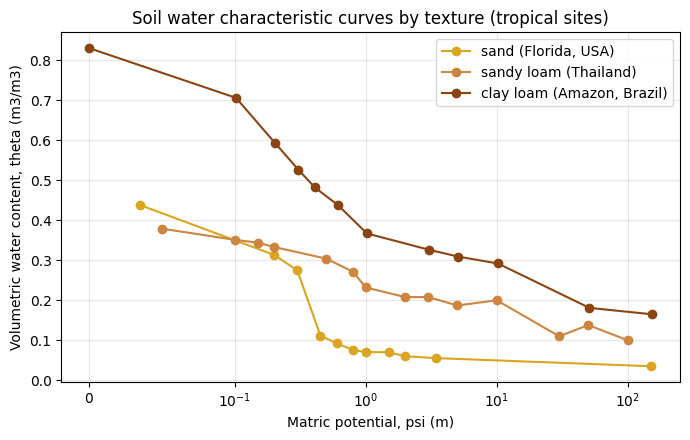

In [80]:
curve_ids = ["Florida_ksat_data_1000", "S.Konyai_2006_KK1", "HYBRAS405"]
labels = ["sand (Florida, USA)", "sandy loam (Thailand)", "clay loam (Amazon, Brazil)"]
colors = ["goldenrod", "peru", "saddlebrown"]

plt.figure(figsize=(7, 4.5))
for curve_id, label, color in zip(curve_ids, labels, colors):
    curve = good_clean[good_clean["layer_id"] == curve_id].sort_values("lab_head_m")
    plt.plot(curve["lab_head_m"], curve["lab_wrc"], "o-", color=color, label=label)

plt.xscale("symlog", linthresh=0.1)
plt.xlabel("Matric potential, psi (m)")
plt.ylabel("Volumetric water content, theta (m3/m3)")
plt.title("Soil water characteristic curves by texture (tropical sites)")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

All three curves are classified as Tropical, with texture ranging from sand to clay loam: `Florida_ksat_data_1000` (sand), `S.Konyai_2006_KK1` (sandy loam, Thailand) and `HYBRAS405` (clay loam, Amazon basin, used again on its own later). Together they show that the same matric potential can correspond to very different amounts of water depending on the soil's texture.

In [81]:
counts = good.groupby("climate_classes")["layer_id"].nunique().sort_values(ascending=False)
counts

climate_classes
Temperate    7954
Boreal       1641
Tropical     1122
Arid          974
Polar          14
Name: layer_id, dtype: int64

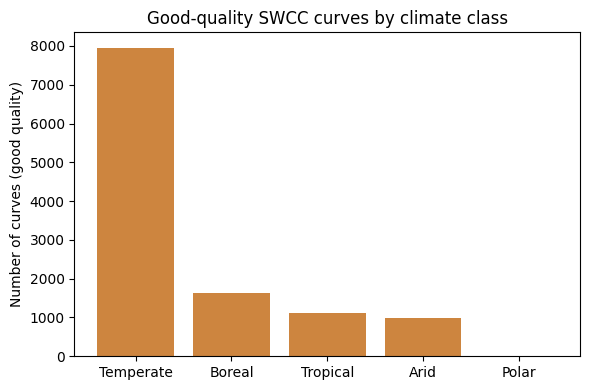

In [82]:
plt.figure(figsize=(6, 4))
plt.bar(counts.index, counts.values, color="peru")
plt.ylabel("Number of curves (good quality)")
plt.title("Good-quality SWCC curves by climate class")
plt.tight_layout()
plt.show()

The two plots above only show a few hand-picked curves. To get a sense of the dataset as a whole, I plot every individual (psi, theta) point at once, as small, mostly transparent dots instead of connected lines. A line would zig-zag between points that belong to completely different curves and would not mean anything. Where many points land on top of each other the region simply looks darker, which gives an honest sense of density instead of just the range of values. I exclude here the 5 rows with no water content and the 51 points with an implausible matric potential found earlier.

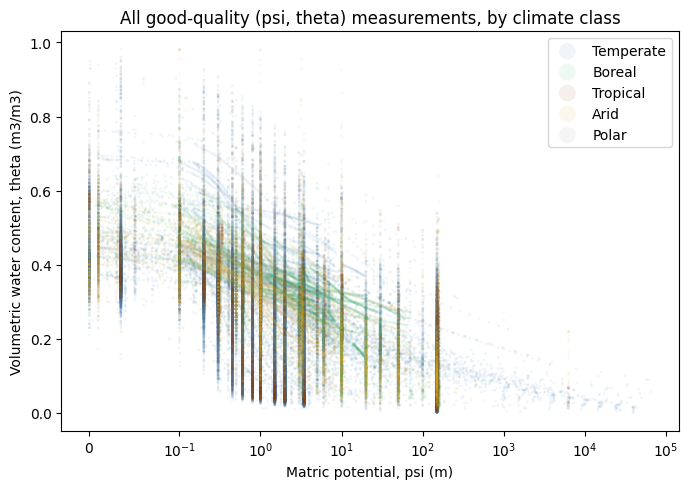

In [83]:
climate_colors = {
    "Temperate": "steelblue", "Boreal": "mediumseagreen", "Tropical": "saddlebrown",
    "Arid": "goldenrod", "Polar": "gray",
}

plt.figure(figsize=(7, 5))
for climate, color in climate_colors.items():
    subset = plot_rows[plot_rows["climate_classes"] == climate]
    plt.scatter(subset["lab_head_m"], subset["lab_wrc"], s=4, alpha=0.08, color=color, label=climate, edgecolors="none")

plt.xscale("symlog", linthresh=0.1)
plt.xlabel("Matric potential, psi (m)")
plt.ylabel("Volumetric water content, theta (m3/m3)")
plt.title("All good-quality (psi, theta) measurements, by climate class")
plt.legend(markerscale=6)
plt.tight_layout()
plt.show()

## OOP for data processing

I split the processing into two classes with different jobs. `SoilRetentionCurve` holds the measured data of one curve and knows how to work with it directly (sorting the points, interpolating, converting to effective saturation). `VanGenuchtenModel`, defined further down, holds the mathematical model and knows how to fit itself to a curve. Keeping these separate means I could swap in a different retention model later without touching the class that manages the raw data.

In [84]:
class SoilRetentionCurve:
    def __init__(self, layer_id, psi, theta):
        order = np.argsort(psi)
        self.layer_id = layer_id
        self.psi = np.array(psi)[order]
        self.theta = np.array(theta)[order]

    def interpolate(self, psi_grid):
        return np.interp(psi_grid, self.psi, self.theta)

    def effective_saturation(self, theta_r, theta_s):
        return (self.theta - theta_r) / (theta_s - theta_r)


In [85]:
row = good_clean[good_clean["layer_id"] == "HYBRAS405"]
hybras_curve = SoilRetentionCurve("HYBRAS405", row["lab_head_m"].values, row["lab_wrc"].values)

print(hybras_curve.psi)
print(hybras_curve.theta)

[0.00e+00 1.02e-01 2.04e-01 3.06e-01 4.08e-01 6.12e-01 1.02e+00 3.06e+00
 5.10e+00 1.02e+01 5.10e+01 1.53e+02]
[0.83  0.706 0.592 0.526 0.482 0.438 0.367 0.326 0.309 0.292 0.181 0.165]


In [86]:
print(hybras_curve.interpolate([1, 20, 100]))

[0.37048039 0.26533824 0.17331373]


In [87]:
thetar = row["thetar"].iloc[0]
thetas = row["thetas"].iloc[0]
print(hybras_curve.effective_saturation(thetar, thetas))

[0.97137016 0.79654704 0.63582256 0.54277154 0.48073753 0.41870352
 0.31860318 0.26079876 0.23683108 0.21286339 0.0563685  0.03381068]


In [88]:
interp_table = pd.DataFrame({
    "psi (m)": [1, 20, 100],
    "interpolated theta": hybras_curve.interpolate([1, 20, 100]),
})
interp_table

,psi (m),interpolated theta
0,1,0.370480
1,20,0.265338
2,100,0.173314


In [89]:
sat_table = pd.DataFrame({
    "psi (m)": hybras_curve.psi,
    "theta (measured)": hybras_curve.theta,
    "effective saturation": hybras_curve.effective_saturation(thetar, thetas),
})
sat_table

,psi (m),theta (measured),effective saturation
0,0.000,0.830,0.971370
1,0.102,0.706,0.796547
2,0.204,0.592,0.635823
3,0.306,0.526,0.542772
4,0.408,0.482,0.480738
5,0.612,0.438,0.418704
6,1.020,0.367,0.318603
7,3.060,0.326,0.260799
8,5.100,0.309,0.236831
9,10.200,0.292,0.212863


`VanGenuchtenModel` implements the equation I mentioned in the Context section:

$$
\theta(\psi) = \theta_r + \frac{\theta_s - \theta_r}{\left[1 + (\alpha \psi)^n\right]^m},
\qquad m = 1 - \frac{1}{n}
$$

Here $\psi$ is the matric potential, $\theta$ the water content, and $\alpha$, $n$, $\theta_r$, $\theta_s$ are the four numbers that give the curve its shape and its wet and dry limits. The restriction $m = 1 - 1/n$ is the standard simplification used for basically every curve in this dataset.

Fitting means finding the four unknowns that make the equation match the measured points as closely as possible, and `scipy.optimize.curve_fit` does exactly that: given the function, the measured pairs, and a starting guess, it searches for the combination that leaves the smallest gap between curve and data. The starting guess (`p0`) matters because the search does not start from nothing, it starts there and adjusts step by step, so a bad guess can make it converge slowly or not at all. I use the minimum and maximum measured water content as the starting guess for $\theta_r$ and $\theta_s$, since the real values can never fall outside that range.

In [90]:
from scipy.optimize import curve_fit


def van_genuchten(psi, alpha, n, theta_r, theta_s):
    m = 1 - 1 / n
    return theta_r + (theta_s - theta_r) / (1 + (alpha * psi) ** n) ** m


class VanGenuchtenModel:
    def __init__(self):
        self.params = None

    def fit(self, curve):
        p0 = [1.0, 1.5, curve.theta.min(), curve.theta.max()]
        params, _ = curve_fit(van_genuchten, curve.psi, curve.theta, p0=p0, maxfev=10000)
        self.params = params
        return self

    def __call__(self, psi):
        return van_genuchten(psi, *self.params)

    def residuals(self, curve):
        return curve.theta - self(curve.psi)

In [91]:
model = VanGenuchtenModel().fit(hybras_curve)

fit_table = pd.DataFrame({
    "parameter": ["alpha", "n", "theta_r", "theta_s"],
    "fitted here": model.params,
    "from CSV": [row["alpha"].iloc[0], row["n"].iloc[0], row["thetar"].iloc[0], row["thetas"].iloc[0]],
})
fit_table

,parameter,fitted here,from CSV
0,alpha,13.579605,14.852685
1,n,1.379157,1.370446
2,theta_r,0.144244,0.141018
3,theta_s,0.837009,0.850307


In [92]:
residual_table = pd.DataFrame({
    "psi (m)": hybras_curve.psi,
    "theta (measured)": hybras_curve.theta,
    "theta (fitted model)": model(hybras_curve.psi),
    "residual": model.residuals(hybras_curve),
})
residual_table

,psi (m),theta (measured),theta (fitted model),residual
0,0.000,0.830,0.837009,-0.007009
1,0.102,0.706,0.678828,0.027172
2,0.204,0.592,0.587454,0.004546
3,0.306,0.526,0.533619,-0.007619
4,0.408,0.482,0.497350,-0.015350
5,0.612,0.438,0.450179,-0.012179
6,1.020,0.367,0.398133,-0.031133
7,3.060,0.326,0.312582,0.013418
8,5.100,0.309,0.283054,0.025946
9,10.200,0.292,0.251025,0.040975


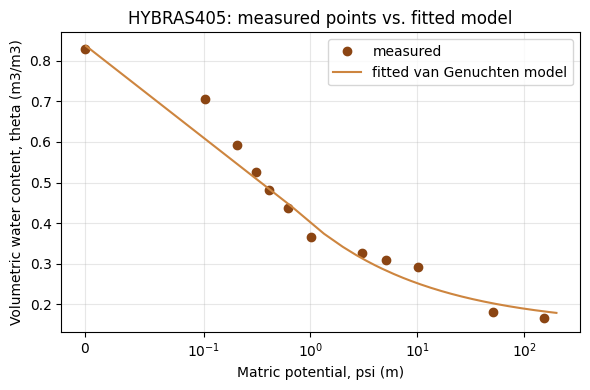

In [93]:
psi_smooth = np.linspace(0.001, 200, 300)

plt.figure(figsize=(6, 4))
plt.plot(hybras_curve.psi, hybras_curve.theta, "o", color="saddlebrown", label="measured")
plt.plot(psi_smooth, model(psi_smooth), "-", color="peru", label="fitted van Genuchten model")
plt.xscale("symlog", linthresh=0.1)
plt.xlabel("Matric potential, psi (m)")
plt.ylabel("Volumetric water content, theta (m3/m3)")
plt.title("HYBRAS405: measured points vs. fitted model")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

## Numerical derivation or integration of data

A derivative measures how fast something changes. Here what changes is the water content (theta) as the matric potential (psi) goes up, so $d\theta/d\psi$ answers a practical question: for a small increase in dryness, how much water does the soil actually give up? In soil physics this is called the specific water capacity, and it matters for irrigation. A soil with a large specific water capacity around normal field conditions gives up water easily as it dries, while a soil with a small value holds on tightly and needs less frequent watering.

I compute the derivative on the fitted van Genuchten curve, not on the 12 raw points directly, for the same reason as before: straight lines between raw points have sharp corners that mean nothing physically, while the fitted curve is smooth everywhere, so its derivative is too.

I could work out the exact derivative of the van Genuchten equation by hand with calculus, but the point of this section is to approximate it numerically instead, the same way it was done in class: pick two nearby points on the curve and use the slope of the line between them as a stand-in for the slope at that exact spot.

Forward difference uses the point itself and one small step ahead, $h$:

$$
\frac{df}{dx} \approx \frac{f(x+h) - f(x)}{h}
$$

Central difference uses one small step on each side instead:

$$
\frac{df}{dx} \approx \frac{f(x+h) - f(x-h)}{2h}
$$

Central is usually more accurate for the same $h$, because it looks at both sides of the point and the errors from each side partly cancel out, while forward only looks ahead and keeps the full error from that one direction.

In [94]:
class Derivative:
    def __init__(self, func, h=1e-4):
        self.func = func
        self.h = h


class ForwardDiff(Derivative):
    def __call__(self, psi):
        return (self.func(psi + self.h) - self.func(psi)) / self.h


class CentralDiff(Derivative):
    def __call__(self, psi):
        if np.any(psi - self.h < 0):
            return (self.func(psi + self.h) - self.func(psi)) / self.h
        else:
            return (self.func(psi + self.h) - self.func(psi - self.h)) / (2 * self.h)

In [95]:
d_forward = ForwardDiff(model)
d_central = CentralDiff(model)

psi_query = np.array([0.5, 1, 5, 10, 50, 100])
derivative_table = pd.DataFrame({
    "psi (m)": psi_query,
    "dtheta/dpsi (forward)": d_forward(psi_query),
    "dtheta/dpsi (central)": d_central(psi_query),
})
derivative_table

,psi (m),dtheta/dpsi (forward),dtheta/dpsi (central)
0,0.5,-0.232740,-0.232769
1,1.0,-0.094378,-0.094385
2,5.0,-0.010574,-0.010574
3,10.0,-0.004074,-0.004074
4,50.0,-0.000443,-0.000443
5,100.0,-0.000170,-0.000170


Plotting the derivative over the same range as the retention curve shows where the soil gives up water fastest.

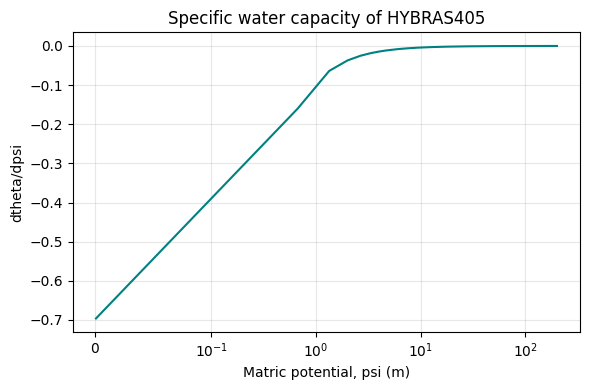

In [96]:
psi_smooth = np.linspace(0.001, 200, 300)
dtheta = d_central(psi_smooth)

plt.figure(figsize=(6, 4))
plt.plot(psi_smooth, dtheta, color="teal")
plt.xscale("symlog", linthresh=0.1)
plt.xlabel("Matric potential, psi (m)")
plt.ylabel("dtheta/dpsi")
plt.title("Specific water capacity of HYBRAS405")
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

The derivative is negative everywhere, which makes sense physically: as psi goes up the soil is drier, so theta can only go down, never up, the same rule I used earlier to catch the impossible points in the raw data. The curve is steepest near saturation, roughly psi = 0 to 1 m, where dtheta/dpsi reaches about -0.7, meaning the soil gives up water very fast there for a small increase in dryness. Past about psi = 10 m it flattens out close to zero, meaning the soil barely gives up any more water no matter how much drier it gets. For irrigation that means watering is most effective in the steep region, where a small change in dryness frees up a lot of water, and much less effective once you are in the flat part.

## Matrix operations

A matrix is ​​constructed from 40 randomly selected soil-water retention curves for tropical soils, using a fixed seed to ensure reproducibility. Each curve is interpolated at the same 8 matric potential values ​​using `SoilRetentionCurve.interpolate` (the same method defined in the object-oriented programming section), such that each row of the resulting matrix corresponds to a curve and each column to a matric potential value.

In [97]:
tropical = good_clean[good_clean["climate_classes"] == "Tropical"]
counts = tropical.groupby("layer_id").agg(n_points=("lab_head_m", "size"), max_psi=("lab_head_m", "max"))
usable_ids = counts[(counts["n_points"] >= 6) & (counts["max_psi"] >= 10)].index

rng = np.random.RandomState(42)
chosen_ids = rng.choice(usable_ids, size=40, replace=False)

psi_grid = np.array([0.1, 0.5, 1, 3.3, 10, 33, 100, 150])

def curve_row(layer_id):
    sub = tropical[tropical["layer_id"] == layer_id]
    curve = SoilRetentionCurve(layer_id, sub["lab_head_m"].values, sub["lab_wrc"].values)
    return curve.interpolate(psi_grid)

matrix = np.array([curve_row(lid) for lid in chosen_ids])
print("matrix shape:", matrix.shape)
matrix

matrix shape: (40, 8)


array([[0.41745098, 0.24586275, 0.19807843, 0.16886383, 0.14544118,
        0.13158824, 0.11955882, 0.11808824],
       [0.50009804, 0.31854902, 0.26207843, 0.23189362, 0.2182451 ,
        0.20347059, 0.19007843, 0.18811765],
       [0.404     , 0.34356188, 0.307     , 0.2802298 , 0.25881173,
        0.25140601, 0.22983284, 0.21373346],
       [0.6929085 , 0.64454248, 0.62053922, 0.59186383, 0.5521713 ,
        0.53886555, 0.50320728, 0.47659664],
       [0.4260027 , 0.41621433, 0.39565   , 0.33832759, 0.3299296 ,
        0.31019386, 0.25270279, 0.209799  ],
       [0.50017647, 0.44620042, 0.3812549 , 0.3634766 , 0.31683333,
        0.31136975, 0.29776331, 0.28760924],
       [0.539     , 0.47397657, 0.44322987, 0.38378723, 0.30691176,
        0.30308403, 0.29745378, 0.2932521 ],
       [0.33183636, 0.133     , 0.086     , 0.06291379, 0.06080553,
        0.0559089 , 0.04164483, 0.031     ],
       [0.38007879, 0.176211  , 0.0762    , 0.04757928, 0.04597762,
        0.04256317, 0.032616

# Discussion

The source file contained 4,542 exact duplicate rows, furthermore, among the 112,708 point measurements marked as reliable, there were 5 with no water content data and 51 with a matric potential exceeding 100,000 m all originating from the same source, `Belgium_database`. A second issue—an increase rather than a decrease in water content observed in 858 of the 11,705 curves could not be attributed to a single cause, consequently, this was retained in the analysis as a documented limitation rather than applying an arbitrary exclusion criterion.
Soil texture comparisons confirmed that the same matric potential corresponds to vastly different water contents depending on whether the soil is sandy or clayey. The van Genuchten model yielded values ​​close to the published parameters for this curve, representing a satisfactory cross-validation for both cases.

The specific water capacity curve, dθ/dψ, reveals the point at which the soil is most sensitive to changes in dryness. This aspect is relevant to the acquisition module for specific objective 1: the sensor requires maximum precision in this steep-slope zone, where a minor signal error translates into the greatest error in water content estimation.
A genuine limitation is that tropical soils account for only about 10% of the high quality curves in the database (1,122 out of 11,705), the analysis is therefore based on a smaller sample than would be available for temperate soils. A second limitation, previously noted in the context section, is that none of this involves an actual electromagnetic signal, given that the sensor has not yet been built. Instead, an operational workflow is available tested against a real dataset containing authentic quality issues that is ready to process actual measurements once they become available.

# Conclusions

This work resulted in a comprehensive workflow developed around a real, publicly accessible dataset regarding soil hydraulic properties: data were loaded and cleaned by applying evidence-based criteria rather than assumptions, the retention curve and the van Genuchten model were separated into two distinct classes, a numerical derivative consistent with the curve's physics was calculated, and 40 curves were synthesized using matrix operations, revealing a dominant variation pattern in tropical soils.

Two aspects of this work carry over to the next stage of the thesis. First, the comparison of soil textures confirmed, using real data, that matric potential alone does not determine water content, hence the need to combine the electromagnetic signal with physical properties to address the second specific objective. Second, the same criterion applied during data cleaning—based on a rule supported by clear evidence (the upper limit of matric potential, linked to a specific source) and the exclusion of data lacking solid justification (abrupt jumps in water content) will be necessary when actual measurements from the electromagnetic module begin to be received, prior to validating their reliability.

# References

- Gupta, S., Papritz, A., Lehmann, P., Hengl, T., Bonetti, S., & Or, D. (2022). Global Soil
  Hydraulic Properties dataset based on legacy site observations and robust parameterization.
  *Scientific Data*, 9, 444. https://doi.org/10.1038/s41597-022-01481-5

- Ottoni, M. V., Ottoni Filho, T. B., Schaap, M. G., Lopes-Assad, M. L. R., & Rotunno Filho,
  O. C. (2018). Hydrophysical database for Brazilian soils (HYBRAS) and pedotransfer functions
  for water retention. *Vadose Zone Journal*, 17(1). https://doi.org/10.2136/vzj2017.05.0095

- Topp, G. C., Davis, J. L., & Annan, A. P. (1980). Electromagnetic determination of soil water
  content: Measurements in coaxial transmission lines. *Water Resources Research*, 16(3),
  574-582. https://doi.org/10.1029/WR016i003p00574

- van Genuchten, M. T. (1980). A closed-form equation for predicting the hydraulic conductivity
  of unsaturated soils. *Soil Science Society of America Journal*, 44(5), 892-898.
  https://doi.org/10.2136/sssaj1980.03615995004400050002x

- Zaman, I., Jain, N., & Förster, A. (2021). Machine learning based soil VWC and field capacity
  estimation using low cost sensors. arXiv:2102.03354. https://arxiv.org/abs/2102.03354